# Proyecto Integrador - Metodos Numericos
## Segunda entrega: implementacion reproducible

Universidad Externado de Colombia, Pregrado en Ciencia de Datos, 2026-2. Equipo: Ailyn Sofia Gomez Rodriguez, Julian Camilo Jimenez y Julian Steven Duarte. Docente: Edwin Fernando Munoz Chipatecua.

Este cuaderno implementa M1 y M2 del articulo de Jerezano, Chicharro y Garrido-Saez y los compara con Newton modificado, Steffensen modificado y el competidor KK. Ejecutar las celdas en orden. No se necesitan datos externos. Entorno recomendado: Python 3.10+ con mpmath, pandas y matplotlib. Si hace falta, instale con `%pip install mpmath pandas matplotlib`.

## 1. Metodo

Para una raiz de multiplicidad conocida m, el articulo define `w=x+beta*g(x)^2`, la pendiente `D=(g(w)-g(x))/(w-x)`, el predictor `y=x-m*g(x)/D`, `t=exp(Log(g(y)/g(x))/m) con Log principal complejo` y el corrector `x_nuevo=x-m*H(t)*g(x)/D`. Se comparan `H1(t)=1+t+2*t^2` y `H2(t)=(1-t)/(1-2*t)`. Bajo las hipotesis del articulo tienen orden cuatro con tres evaluaciones funcionales por paso. Newton modificado y Steffensen modificado son lineas base de orden dos. Tambien se implementa KK, un competidor sin derivadas de orden cuatro del articulo.

In [1]:
from time import perf_counter
from pathlib import Path
import mpmath as mp
import math
import pandas as pd
import matplotlib.pyplot as plt
mp.mp.dps=150
TOL=mp.mpf('1e-25')
MAX_ITER=100
BETA=mp.mpf('0.01')
print('precision',mp.mp.dps,'tolerancia',mp.nstr(TOL))

precision 150 tolerancia 1.0e-25


## 2. Benchmarks deterministas

Las funciones son los problemas del articulo. Para Planck se eleva al cubo la ecuacion `exp(-x)-1+x/5=0`; no debe confundirse con `exp(-x)-1+x^3/5`. Las raices de referencia se usan solo para medir el error. Las semillas quedan fijadas explicitamente.

In [2]:
def g1(x): return x**3-mp.mpf('5.22')*x**2+mp.mpf('9.0825')*x-mp.mpf('5.2675')
def dg1(x): return 3*x**2-mp.mpf('10.44')*x+mp.mpf('9.0825')
def hp(x): return mp.exp(-x)-1+x/5
def g2(x): return hp(x)**3
def dg2(x): return 3*hp(x)**2*(-mp.exp(-x)+mp.mpf(1)/5)
def g3(x): return x**9-29*x**8+349*x**7-2261*x**6+8455*x**5-17663*x**4+15927*x**3+6993*x**2-24732*x+12960
def dg3(x): return 9*x**8-232*x**7+2443*x**6-13566*x**5+42275*x**4-70652*x**3+47781*x**2+13986*x-24732
benchmarks=[
 {'id':'g1 doble','g':g1,'dg':dg1,'m':2,'alpha':mp.mpf('1.75'),'seeds':['1.9','3.0']},
 {'id':'g2 Planck triple','g':g2,'dg':dg2,'m':3,'alpha':mp.findroot(lambda z: mp.exp(-z)-1+z/5, mp.mpf('5')),'seeds':['5.3','10.0']},
 {'id':'g3 cuádruple','g':g3,'dg':dg3,'m':4,'alpha':mp.mpf('3.0'),'seeds':['2.8','3.4']}]
print('Problemas definidos:',len(benchmarks))

Problemas definidos: 3


## 3. Solucionador y manejo de fallos

Las semillas y raices de referencia son reales, pero la rama principal compleja para t permite trayectorias complejas. Se registran nodos coincidentes, denominadores nulos, estancamiento y limite de iteraciones. La parada exige paso y residuo bajo tolerancia.

In [3]:
def principal_root(z,m):
 # Rama principal compleja, como en la definicion del articulo.
 z=mp.mpc(z)
 if z==0: return mp.mpc(0)
 return mp.exp(mp.log(z)/m)
def dd(g,a,b):
 if a==b: raise ZeroDivisionError('nodos coincidentes')
 return (g(a)-g(b))/(a-b)
def solve(method,g,dg,m,x0,beta=BETA,tol=TOL,max_iter=MAX_ITER):
 n_g=0; n_dg=0
 def fg(z):
  nonlocal n_g
  n_g+=1
  return g(z)
 def fdg(z):
  nonlocal n_dg
  n_dg+=1
  return dg(z)
 x=mp.mpf(x0); gx=fg(x); xs=[x]; steps=[]; residuals=[abs(gx)]; status='maximo de iteraciones'; start=perf_counter()
 for k in range(1,max_iter+1):
  if abs(gx)<=tol and steps and steps[-1]<=tol:
   status='convergio'; break
  try:
   if method in ('M1','M2','Steffensen','KK'):
    w=x+beta*(gx**2 if method in ('M1','M2') else gx)
    if w==x: status='estancamiento w=x'; break
    gw=fg(w); d=(gw-gx)/(w-x)
    if d==0: raise ZeroDivisionError('pendiente nula')
    if method=='Steffensen': xn=x-m*gx/d
    elif method=='KK':
     y=x-m*gx/d; gy=fg(y); t=principal_root(gy/gx,m)
     if w==y: raise ZeroDivisionError('nodos KK coincidentes')
     dwy=(gw-gy)/(w-y)
     if 1-2*t==0: raise ZeroDivisionError('polo KK')
     den=d+2*dwy
     if den==0: raise ZeroDivisionError('denominador KK nulo')
     xn=y-((m+2)*t/(1-2*t))*gx/den
    else:
     y=x-m*gx/d; t=principal_root(fg(y)/gx,m)
     if method=='M1': H=1+t+2*t**2
     else:
      if 1-2*t==0: raise ZeroDivisionError('polo H2')
      H=(1-t)/(1-2*t)
     xn=x-m*H*gx/d
   elif method=='Newton modificado':
    dx=fdg(x)
    if dx==0: raise ZeroDivisionError('derivada nula')
    xn=x-m*gx/dx
   else: raise ValueError('metodo desconocido')
   step=abs(xn-x); gn=fg(xn); res=abs(gn); xs.append(xn); steps.append(step); residuals.append(res); x=xn; gx=gn
   if step<=tol and res<=tol: status='convergio'; break
  except (ValueError,ZeroDivisionError,OverflowError) as exc:
   status='fallo: '+str(exc); break
 acoc=None
 if len(xs)>=4:
  e1,e2,e3=abs(xs[-1]-xs[-2]),abs(xs[-2]-xs[-3]),abs(xs[-3]-xs[-4])
  if min(e1,e2,e3)>0 and mp.log(e2/e3)!=0: acoc=float(mp.log(e1/e2)/mp.log(e2/e3))
 return {'status':status,'iterations':len(steps),'x':x,'step':steps[-1] if steps else mp.inf,'residual':abs(gx),'acoc':acoc,'ms':1000*(perf_counter()-start),'g_evals':n_g,'dg_evals':n_dg,'residuals':residuals,'xs':xs}
print('Solucionador definido')

Solucionador definido


## 4. Corridas, tabla y archivo CSV

La tabla conserva todos los estados, incluidos los fallos. La tabla tambien cuenta evaluaciones de g y de g prima, incluido el calculo del residuo usado para verificar la parada. El tiempo se ofrece como referencia local; puede variar entre corridas y equipos. El CSV se guarda en la carpeta resultados de la segunda entrega.

In [4]:
methods=['M1','M2','Newton modificado','Steffensen','KK']
rows=[]; history={}
for b in benchmarks:
 for seed in b['seeds']:
  for method in methods:
   r=solve(method,b['g'],b['dg'],b['m'],seed); times=[r['ms']]
   for _ in range(49): times.append(solve(method,b['g'],b['dg'],b['m'],seed)['ms'])
   r['ms']=sum(times)/len(times); history[(b['id'],seed,method)]=r
   rows.append({'problema':b['id'],'m':b['m'],'semilla':seed,'metodo':method,'estado':r['status'],'iteraciones':r['iterations'],'eval_g':r['g_evals'],'eval_gprima':r['dg_evals'],'error_abs':mp.nstr(abs(r['x']-b['alpha']),8),'residuo':mp.nstr(r['residual'],8),'ACOC':r['acoc'],'tiempo_ms':round(r['ms'],4)})
results=pd.DataFrame(rows)
display(results)
cwd=Path.cwd()
if (cwd/'segunda entrega'/'resultados').is_dir():
    project_dir=cwd/'segunda entrega'
elif (cwd.parent/'resultados').is_dir():
    project_dir=cwd.parent
else:
    project_dir=cwd
results_dir=project_dir/'resultados'
results_dir.mkdir(exist_ok=True)
csv_path=results_dir/'resultados_fase2.csv'
results.to_csv(csv_path,index=False)
print('Guardado:',csv_path)

,problema,m,semilla,metodo,estado,iteraciones,eval_g,eval_gprima,error_abs,residuo,ACOC,tiempo_ms
0,g1 doble,2,1.9,M1,convergio,5,16,0,1.3237786e-35,5.2571697e-72,8.805070e+00,0.9267
1,g1 doble,2,1.9,M2,estancamiento w=x,4,13,0,2.033342e-50,1.2403439e-101,3.808213e+00,0.7627
2,g1 doble,2,1.9,Newton modificado,convergio,8,9,8,1.6913901e-57,8.5824009e-116,2.000000e+00,0.4233
3,g1 doble,2,1.9,Steffensen,convergio,8,17,0,1.7731236e-57,9.4319018e-116,2.000000e+00,0.5144
4,g1 doble,2,1.9,KK,fallo: pendiente nula,4,14,0,1.0097648e-53,3.0588751e-108,3.860955e+00,0.9744
5,g1 doble,2,3.0,M1,fallo: pendiente nula,5,17,0,3.3358519e-30,3.3383724e-61,3.380872e+00,1.0107
6,g1 doble,2,3.0,M2,estancamiento w=x,5,16,0,1.5589612e-52,7.2910802e-106,3.829624e+00,1.1048
7,g1 doble,2,3.0,Newton modificado,convergio,10,11,10,2.6148695e-62,2.0512628e-125,2.000000e+00,0.5210
8,g1 doble,2,3.0,Steffensen,convergio,10,21,0,5.519647e-61,9.1399508e-123,2.000000e+00,0.6282
9,g1 doble,2,3.0,KK,convergio,6,19,0,1.6281571e-55,7.9526864e-112,5.911201e+00,1.1681


Guardado: /home/julianxd/code/metodos/segunda entrega/resultados/resultados_fase2.csv


## 5. Sensibilidad al parametro beta

La primera entrega propuso explorar beta = 0.001, 0.01 y 1.0. Aqui repetimos M1 y M2 para cada benchmark y semilla con esos tres valores. El experimento no calcula una cuenca completa de atraccion; permite comparar solo las condiciones iniciales ensayadas. Los fallos quedan incluidos.

In [5]:
beta_records=[]
for b in benchmarks:
    for seed in b["seeds"]:
        for beta_value in (mp.mpf('0.001'),mp.mpf('0.01'),mp.mpf('1.0')):
            for method in ("M1","M2"):
                r=solve(method,b["g"],b["dg"],b["m"],seed,beta=beta_value)
                beta_records.append({
                    "problema":b["id"],"semilla":seed,"beta":mp.nstr(beta_value),
                    "metodo":method,"estado":r["status"],
                    "iteraciones":r["iterations"],
                    "error_abs":mp.nstr(abs(r["x"]-b["alpha"]),8),
                    "residuo":mp.nstr(r["residual"],8)})
beta_sensitivity=pd.DataFrame(beta_records)
display(beta_sensitivity)
beta_sensitivity.to_csv(results_dir/"sensibilidad_beta.csv",index=False)
print("Sensibilidad exportada:",results_dir/"sensibilidad_beta.csv")

,problema,semilla,beta,metodo,estado,iteraciones,error_abs,residuo
0,g1 doble,1.9,0.001,M1,convergio,5,1.3237058e-35,5.2565915e-72
1,g1 doble,1.9,0.001,M2,estancamiento w=x,4,2.0335165e-50,1.2405568e-101
2,g1 doble,1.9,0.01,M1,convergio,5,1.3237786e-35,5.2571697e-72
3,g1 doble,1.9,0.01,M2,estancamiento w=x,4,2.033342e-50,1.2403439e-101
4,g1 doble,1.9,1.0,M1,convergio,5,1.3318084e-35,5.3211408e-72
5,g1 doble,1.9,1.0,M2,estancamiento w=x,4,2.0142158e-50,1.2171195e-101
6,g1 doble,3.0,0.001,M1,fallo: pendiente nula,5,8.4831368e-31,2.1589083e-62
7,g1 doble,3.0,0.001,M2,estancamiento w=x,5,4.6705423e-51,6.5441896e-103
8,g1 doble,3.0,0.01,M1,fallo: pendiente nula,5,3.3358519e-30,3.3383724e-61
9,g1 doble,3.0,0.01,M2,estancamiento w=x,5,1.5589612e-52,7.2910802e-106


Sensibilidad exportada: /home/julianxd/code/metodos/segunda entrega/resultados/sensibilidad_beta.csv


## 6. Experimento complementario en float64

La primera entrega tambien planteo mostrar absorcion numerica. En doble precision usamos g1, m=2 y beta=0.01; ejecutamos M1 y M2 desde x0=1.9 y detenemos la corrida si w coincide con x o si se anula una pendiente. El umbral observado depende de la trayectoria y de las operaciones de punto flotante.

In [6]:
def solve_float64(method,x0=1.9,max_iter=30):
    def gf(x):
        return x**3-5.22*x**2+9.0825*x-5.2675
    x=float(x0); last_res=abs(gf(x)); status="maximo de iteraciones"; count=0
    for k in range(1,max_iter+1):
        gx=gf(x); w=x+0.01*(gx**2)
        if w==x:
            status="absorcion: w=x"; break
        d=(gf(w)-gx)/(w-x)
        if d==0:
            status="pendiente secante nula"; break
        y=x-2*gx/d; gy=gf(y); ratio=gy/gx
        if ratio<0:
            status="sin raiz real"; break
        t=ratio**0.5
        H=1+t+2*t*t if method=="M1" else (1-t)/(1-2*t)
        if method=="M2" and 1-2*t==0:
            status="polo H2"; break
        xn=x-2*H*gx/d; count=k; last_res=abs(gf(xn))
        if abs(xn-x)<1e-14 and last_res<1e-14:
            x=xn; status="convergio"; break
        x=xn
    return {"metodo":method,"estado":status,"iteraciones":count,
            "ultimo_x":x,"residuo":last_res}
float64_results=pd.DataFrame([solve_float64("M1"),solve_float64("M2")])
display(float64_results)

,metodo,estado,iteraciones,ultimo_x,residuo
0,M1,absorcion: w=x,2,1.750372,4.211540e-09
1,M2,pendiente secante nula,2,1.762096,6.159686e-06


## 5. Grafico de convergencia

Se grafica el residuo de la primera funcion con semilla 1.9. Solo se incluyen valores positivos para la escala logaritmica. Consulte primero la columna estado para interpretar curvas incompletas.

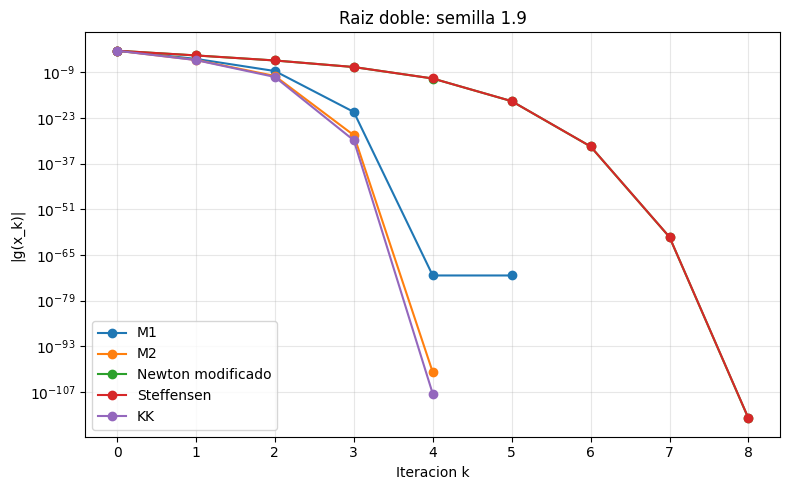

In [7]:
fig,ax=plt.subplots(figsize=(8,5))
b=benchmarks[0]
for method in methods:
 r=history[(b['id'],'1.9',method)]
 ys=[float(q) for q in r['residuals'] if q>0]
 if ys: ax.semilogy(range(len(ys)),ys,marker='o',label=method)
ax.set(xlabel='Iteracion k',ylabel='|g(x_k)|',title='Raiz doble: semilla 1.9')
ax.grid(True,which='both',alpha=.3); ax.legend(); plt.tight_layout(); plt.show()

## 6. Lectura de resultados y declaracion

El ACOC usa tres pasos consecutivos y aproxima el orden local solo cuando ya se alcanzo el regimen asintotico. Un valor aislado no demuestra el orden. Compare residuos, error, estados, evaluaciones funcionales y tiempo, y explique las limitaciones de las semillas probadas. Analisis de resultados: para g1 desde 1.9, M1 converge en cinco pasos, M2 y KK se estancan; desde 3.0, Newton, Steffensen y KK convergen, M1 falla y M2 se estanca. En g2 M1 y M2 se estancan desde ambas semillas, KK converge desde 5.3 y se estanca desde 10. En g3 todos convergen. La Tabla 1 del articulo reporta 7 pasos para M1 y M2 y 6 para KK desde g1 con 1.9; no es comparable directamente con esta corrida de tolerancia 1e-25 frente a 1e-200. Nuestras corridas no confirman el ACOC cuatro. La guia permite apoyo de IA si se declara y no sustituye la comprension ni la implementacion del equipo.